# 06 Spatial Clustering

**Objective:** test whether high and low neighbourhood median rates are geographically clustered, using Global Moran's I and Local Moran's I (LISA) for the complete years 2022-2025.

**Unit of analysis:** 2020 Neighborhood Tabulation Areas (NTAs) with at least 5 listings in the year (see notebook 04). Median rates are from `nta_year_medians.parquet`.

**Spatial weights:** Queen contiguity (neighbours share a border or a corner). This notebook first builds and inspects the weights, including neighbourless polygons ("islands") and disconnected groups, before any statistics are calculated.

In [1]:
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from libpysal import weights

pd.set_option("display.width", 120)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESSED = PROJECT_ROOT / "data" / "raw", PROJECT_ROOT / "data" / "processed"
FIG, TAB, MAPS = PROJECT_ROOT / "outputs" / "figures", PROJECT_ROOT / "outputs" / "tables", PROJECT_ROOT / "maps"

YEARS = [2022, 2023, 2024, 2025]
MIN_LISTINGS = 5

nta = gpd.read_file(RAW / "nta2020.geojson")[["nta2020", "ntaname", "boroname", "ntatype", "geometry"]].to_crs(2263)
nty = pd.read_parquet(PROCESSED / "nta_year_medians.parquet")
elig = nty[nty["n_listings"] >= MIN_LISTINGS].copy()

print("NTA polygons:", len(nta), "| NTA-year medians:", len(nty), "| eligible:", len(elig))
print("Eligible per year:", elig.groupby("year").size().to_dict())

NTA polygons: 262 | NTA-year medians: 730 | eligible: 475
Eligible per year: {2022: 129, 2023: 123, 2024: 125, 2025: 98}


In [2]:
def build_queen(year):
    g = (nta.merge(elig.loc[elig["year"] == year, ["nta2020", "median_rate", "n_listings"]], on="nta2020")
            .reset_index(drop=True))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # we report islands ourselves below
        w = weights.Queen.from_dataframe(g)
    return g, w

queen = {y: build_queen(y) for y in YEARS}

rows = []
for y, (g, w) in queen.items():
    card = pd.Series(w.cardinalities)
    comps = pd.Series(w.component_labels).value_counts()
    rows.append({"year": y, "polygons": w.n, "islands (no neighbours)": len(w.islands),
                 "connected groups": w.n_components, "largest group": int(comps.max()),
                 "mean neighbours": round(card.mean(), 2), "median neighbours": card.median(),
                 "max neighbours": int(card.max())})
print(pd.DataFrame(rows).to_string(index=False))

for y, (g, w) in queen.items():
    print(f"\n{y}: islands ->", list(g.loc[w.islands, "ntaname"]))
    comps = pd.Series(w.component_labels).value_counts().sort_values(ascending=False)
    print(f"{y}: sizes of connected groups ->", comps.tolist())

 year  polygons  islands (no neighbours)  connected groups  largest group  mean neighbours  median neighbours  max neighbours
 2022       129                        5                10            105             3.38                3.0               7
 2023       123                        4                10            103             3.37                3.0               7
 2024       125                        5                11            104             3.36                3.0               7
 2025        98                        4                 9             80             3.27                3.0               7

2022: islands -> ['Bedford Park', 'Throgs Neck-Schuylerville', 'Bayside', 'Queens Village', 'New Dorp-Midland Beach']
2022: sizes of connected groups -> [105, 7, 6, 3, 3, 1, 1, 1, 1, 1]

2023: islands -> ['Throgs Neck-Schuylerville', 'Bayside', 'Queens Village', 'New Dorp-Midland Beach']
2023: sizes of connected groups -> [103, 6, 3, 3, 2, 2, 1, 1, 1, 1]

2024: islan

## 1. Where does the neighbour structure break?
Each eligible NTA is coloured by its connectivity: part of the largest connected group, part of a smaller group, or an island with no neighbours. Neighbours are defined only among NTAs with at least 5 listings in that year, so grey (ineligible) areas can break links.

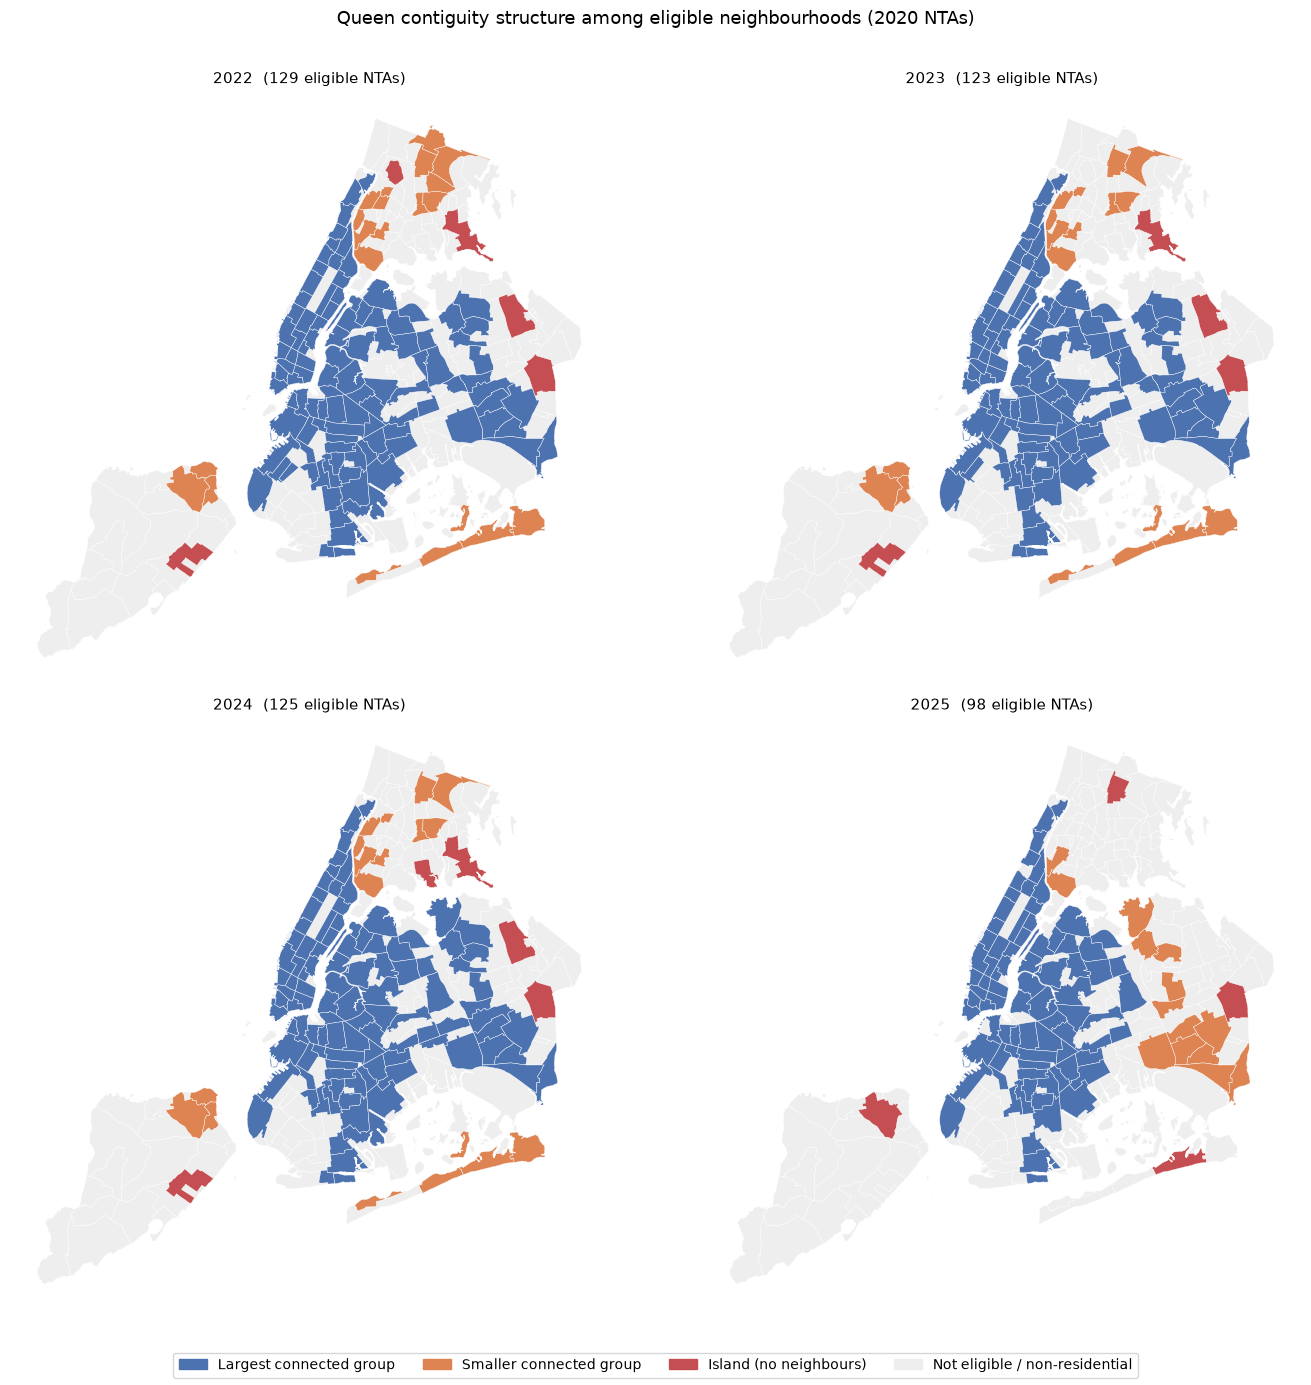


2022: number of eligible NTAs by neighbour count (6 = six or more)
0     5
1    12
2    20
3    30
4    33
5    16
6    13
col_0          Island (no neighbours)  Largest connected group  Smaller connected group
boroname                                                                               
Bronx                               2                        0                       13
Brooklyn                            0                       42                        0
Manhattan                           0                       31                        0
Queens                              2                       32                        3
Staten Island                       1                        0                        3

2023: number of eligible NTAs by neighbour count (6 = six or more)
0     4
1    15
2    18
3    25
4    33
5    15
6    13
col_0          Island (no neighbours)  Largest connected group  Smaller connected group
boroname                                        

In [3]:
from matplotlib.patches import Patch

colors = {"Largest connected group": "#4C72B0",
          "Smaller connected group": "#DD8452",
          "Island (no neighbours)": "#C44E52"}

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
status_by_year = {}
for y, ax in zip(YEARS, axes.ravel()):
    g, w = queen[y]
    lab = pd.Series(w.component_labels, index=g.index)
    biggest = lab.value_counts().idxmax()
    status = pd.Series(np.where(g.index.isin(w.islands), "Island (no neighbours)",
                       np.where(lab == biggest, "Largest connected group", "Smaller connected group")),
                       index=g.index)
    status_by_year[y] = (g, status)

    nta.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)
    for name, c in colors.items():
        sub = g[status == name]
        if len(sub):
            sub.plot(ax=ax, color=c, edgecolor="white", linewidth=0.3)
    ax.set_title(f"{y}  ({len(g)} eligible NTAs)", fontsize=11)
    ax.set_axis_off()

fig.legend(handles=[Patch(color=c, label=n) for n, c in colors.items()] + [Patch(color="#eeeeee", label="Not eligible / non-residential")],
           loc="lower center", ncol=4, fontsize=10)
fig.suptitle("Queen contiguity structure among eligible neighbourhoods (2020 NTAs)", fontsize=13)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.savefig(MAPS / "06_weights_connectivity.png", dpi=150, bbox_inches="tight")
plt.show()

# How many neighbours does each eligible NTA have? And which boroughs hold the islands / small groups?
for y, (g, status) in status_by_year.items():
    w = queen[y][1]
    card = pd.Series(w.cardinalities).clip(upper=6).value_counts().sort_index()
    print(f"\n{y}: number of eligible NTAs by neighbour count (6 = six or more)")
    print(card.to_string())
    print(pd.crosstab(g["boroname"], status).to_string())

## 2. Analysis sets and Global Moran's I
Islands (NTAs with no eligible neighbour) are excluded from the statistics, since they cannot be compared with neighbours; this does not change any other NTA's neighbours. Weights are Queen contiguity, row-standardised. Global Moran's I uses the neighbourhood median rate with 999 permutations (fixed random seed). Significance is judged at p < 0.05; a non-significant result is reported as no evidence of spatial autocorrelation.

In [4]:
analysis = {}
island_rows = []
for y in YEARS:
    g, w = queen[y]
    for nm in g.loc[w.islands, "ntaname"]:
        island_rows.append({"year": y, "island_nta": nm})
    g2 = g[~g.index.isin(w.islands)].reset_index(drop=True)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        w2 = weights.Queen.from_dataframe(g2)
    w2.transform = "r"                       # row-standardised
    analysis[y] = (g2, w2)
    print(f"{y}: {len(g)} eligible -> {len(g2)} analysed | islands left: {len(w2.islands)} | groups: {w2.n_components}")

pd.DataFrame(island_rows).to_csv(TAB / "06_island_ntas.csv", index=False)

2022: 129 eligible -> 124 analysed | islands left: 0 | groups: 5
2023: 123 eligible -> 119 analysed | islands left: 0 | groups: 6
2024: 125 eligible -> 120 analysed | islands left: 0 | groups: 6
2025: 98 eligible -> 94 analysed | islands left: 0 | groups: 5


Global Moran's I

In [5]:
from esda.moran import Moran

rows = []
for y in YEARS:
    g2, w2 = analysis[y]
    np.random.seed(2026)                     # reproducible permutations
    mi = Moran(g2["median_rate"].values, w2, permutations=999)
    rows.append({"year": y, "n_NTAs": len(g2), "Moran_I": mi.I, "expected_I": mi.EI,
                 "z_score": mi.z_sim, "p_value": mi.p_sim,
                 "significant_5pct": mi.p_sim < 0.05})
moran_table = pd.DataFrame(rows)
print(moran_table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
moran_table.to_csv(TAB / "06_global_morans_i.csv", index=False)

 year  n_NTAs  Moran_I  expected_I  z_score  p_value  significant_5pct
 2022     124    0.685      -0.008    9.146    0.001              True
 2023     119    0.687      -0.008    9.286    0.001              True
 2024     120    0.650      -0.008    8.989    0.001              True
 2025      94    0.569      -0.011    6.842    0.001              True


## 3. Local Moran's I (LISA)
Local Moran's I is calculated for each analysed NTA and year (Queen weights, row-standardised, 999 permutations, fixed seed). Each NTA is classified as High-High, Low-Low, High-Low or Low-High only if its pseudo p-value is below 0.05; all others are "Not significant". Because about 100-120 NTAs are tested per year, a stricter classification using the Benjamini-Hochberg false discovery rate (5%) is also reported. Colours are identical in every year.

In [6]:
from esda.moran import Moran_Local

ALPHA = 0.05
QUAD = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}

def bh_threshold(p, alpha=0.05):
    """Benjamini-Hochberg: the largest p-value that can still be called significant at the chosen false discovery rate."""
    p = np.sort(np.asarray(p))
    m = len(p)
    ok = np.where(p <= alpha * np.arange(1, m + 1) / m)[0]
    return p[ok.max()] if len(ok) else 0.0

lisa, fdr_thr = {}, {}
for y in YEARS:
    g2, w2 = analysis[y]
    ml = Moran_Local(g2["median_rate"].values, w2, permutations=999, seed=2026)
    out = g2[["nta2020", "ntaname", "boroname", "median_rate", "n_listings", "geometry"]].copy()
    out["year"] = y
    out["local_I"] = ml.Is
    out["p_sim"] = ml.p_sim
    out["quadrant"] = pd.Series(ml.q, index=out.index).map(QUAD)
    out["cluster_p05"] = np.where(out["p_sim"] < ALPHA, out["quadrant"], "Not significant")
    fdr_thr[y] = bh_threshold(out["p_sim"], ALPHA)
    out["cluster_fdr"] = np.where(out["p_sim"] <= fdr_thr[y], out["quadrant"], "Not significant")
    lisa[y] = out

order = ["High-High", "Low-Low", "High-Low", "Low-High", "Not significant"]
cnt_p = pd.DataFrame({y: lisa[y]["cluster_p05"].value_counts() for y in YEARS}).reindex(order).fillna(0).astype(int)
cnt_f = pd.DataFrame({y: lisa[y]["cluster_fdr"].value_counts() for y in YEARS}).reindex(order).fillna(0).astype(int)

print("Cluster counts, pseudo p < 0.05 (not corrected for multiple testing):")
print(cnt_p.to_string())
print("\nCluster counts after Benjamini-Hochberg FDR (5%):")
print(cnt_f.to_string())
print("\nFDR p-value thresholds:", {y: round(float(t), 3) for y, t in fdr_thr.items()})

for y in YEARS:
    s = lisa[y][lisa[y]["cluster_p05"] != "Not significant"]
    print(f"\n{y}: significant clusters (p < 0.05) by borough")
    print(pd.crosstab(s["boroname"], s["cluster_p05"]).to_string())

allres = pd.concat([lisa[y].drop(columns="geometry") for y in YEARS], ignore_index=True)
allres.to_csv(TAB / "06_lisa_results_2022_2025.csv", index=False)
allres.to_parquet(PROCESSED / "lisa_results.parquet", index=False)

Cluster counts, pseudo p < 0.05 (not corrected for multiple testing):
                 2022  2023  2024  2025
cluster_p05                            
High-High          21    17    17    15
Low-Low            13    11    15    15
High-Low            0     0     0     1
Low-High            0     0     0     1
Not significant    90    91    88    62

Cluster counts after Benjamini-Hochberg FDR (5%):
                 2022  2023  2024  2025
cluster_fdr                            
High-High          14    14    13     7
Low-Low             2     3     4     4
High-Low            0     0     0     0
Low-High            0     0     0     1
Not significant   108   102   103    82

FDR p-value thresholds: {2022: 0.003, 2023: 0.007, 2024: 0.006, 2025: 0.005}

2022: significant clusters (p < 0.05) by borough
cluster_p05  High-High  Low-Low
boroname                       
Bronx                0        4
Brooklyn             3        3
Manhattan           17        0
Queens               1        6

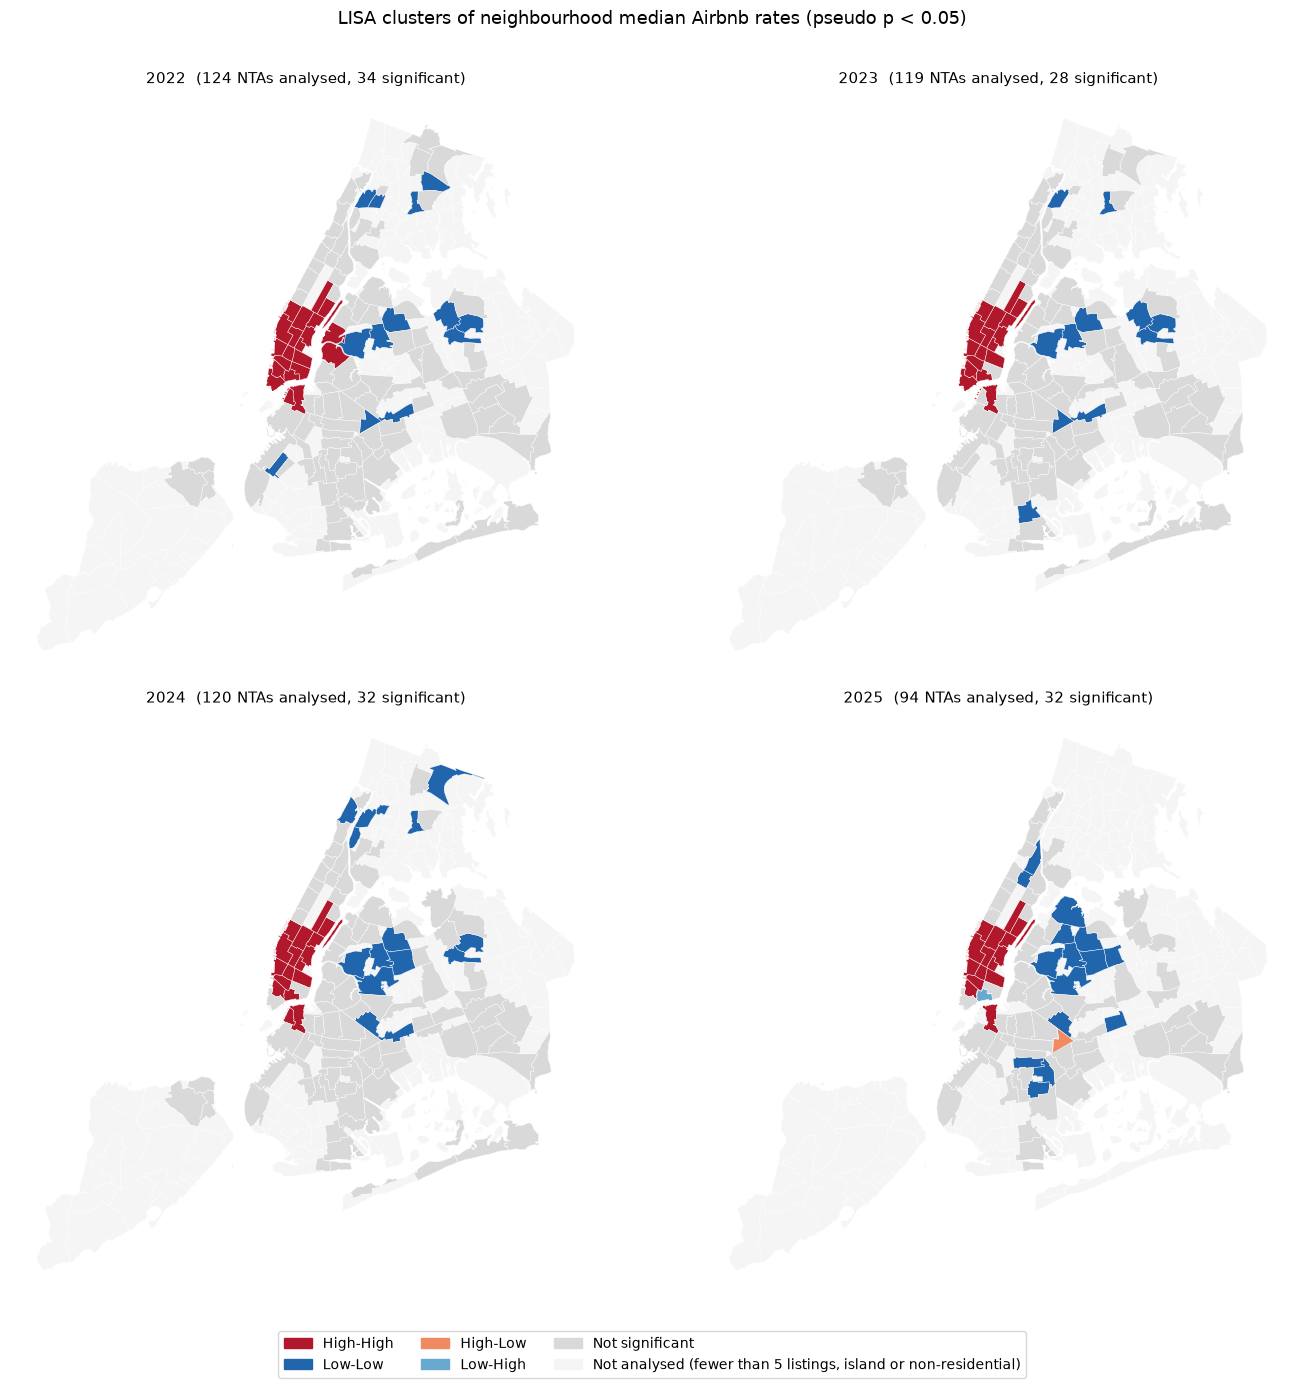

In [7]:
from matplotlib.patches import Patch

COLORS = {"High-High": "#B2182B", "Low-Low": "#2166AC", "High-Low": "#EF8A62",
          "Low-High": "#67A9CF", "Not significant": "#D9D9D9"}
COL = "cluster_p05"

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for y, ax in zip(YEARS, axes.ravel()):
    d = lisa[y]
    nta.plot(ax=ax, color="#F5F5F5", edgecolor="white", linewidth=0.3)
    for name, c in COLORS.items():
        sub = d[d[COL] == name]
        if len(sub):
            sub.plot(ax=ax, color=c, edgecolor="white", linewidth=0.3)
    n_sig = int((d[COL] != "Not significant").sum())
    ax.set_title(f"{y}  ({len(d)} NTAs analysed, {n_sig} significant)", fontsize=11)
    ax.set_axis_off()

handles = [Patch(color=c, label=n) for n, c in COLORS.items()] + [Patch(color="#F5F5F5", label="Not analysed (fewer than 5 listings, island or non-residential)")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10)
label = "pseudo p < 0.05" if COL == "cluster_p05" else "Benjamini-Hochberg FDR 5%"
fig.suptitle(f"LISA clusters of neighbourhood median Airbnb rates ({label})", fontsize=13)
plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig(MAPS / f"06_lisa_{COL}_2022_2025.png", dpi=150, bbox_inches="tight")
plt.show()

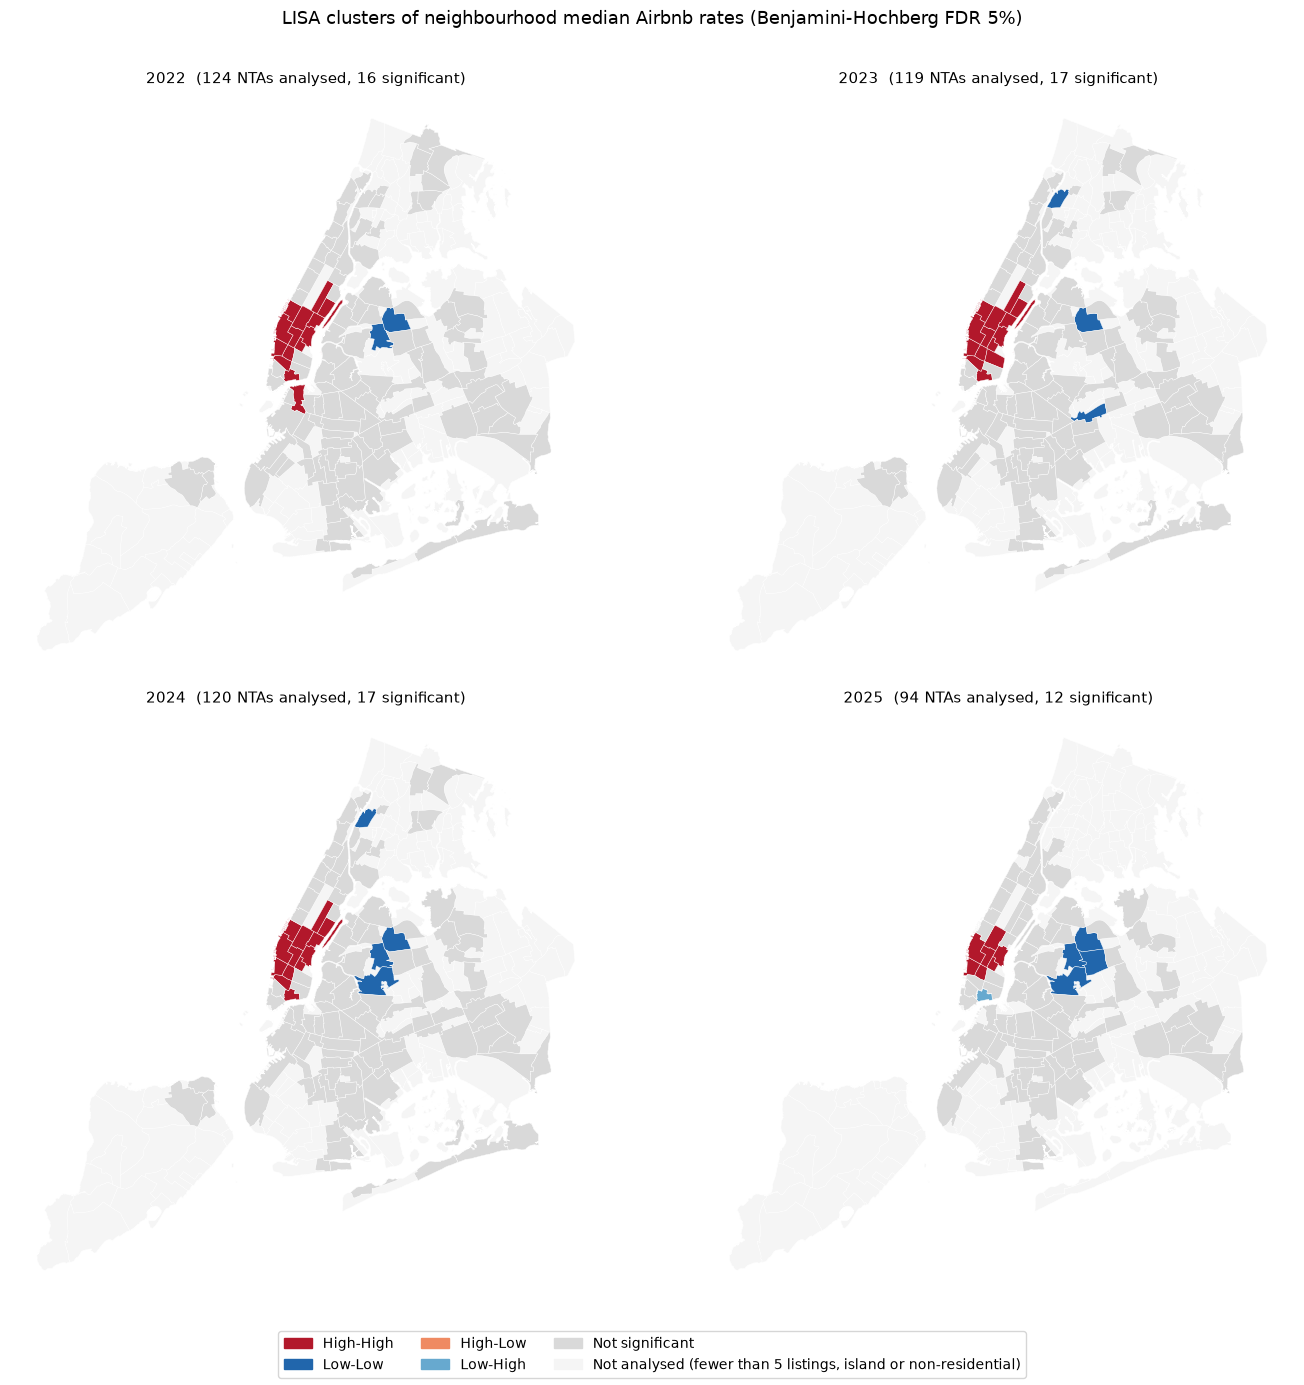

In [8]:
from matplotlib.patches import Patch

COLORS = {"High-High": "#B2182B", "Low-Low": "#2166AC", "High-Low": "#EF8A62",
          "Low-High": "#67A9CF", "Not significant": "#D9D9D9"}

def lisa_map(col, label, filename):
    fig, axes = plt.subplots(2, 2, figsize=(14, 14))
    for y, ax in zip(YEARS, axes.ravel()):
        d = lisa[y]
        nta.plot(ax=ax, color="#F5F5F5", edgecolor="white", linewidth=0.3)
        for name, c in COLORS.items():
            sub = d[d[col] == name]
            if len(sub):
                sub.plot(ax=ax, color=c, edgecolor="white", linewidth=0.3)
        n_sig = int((d[col] != "Not significant").sum())
        ax.set_title(f"{y}  ({len(d)} NTAs analysed, {n_sig} significant)", fontsize=11)
        ax.set_axis_off()
    handles = [Patch(color=c, label=n) for n, c in COLORS.items()]
    handles.append(Patch(color="#F5F5F5", label="Not analysed (fewer than 5 listings, island or non-residential)"))
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10)
    fig.suptitle(f"LISA clusters of neighbourhood median Airbnb rates ({label})", fontsize=13)
    plt.tight_layout(rect=[0, 0.05, 1, 0.97])
    plt.savefig(MAPS / filename, dpi=150, bbox_inches="tight")
    plt.show()

lisa_map("cluster_fdr", "Benjamini-Hochberg FDR 5%", "06_lisa_cluster_fdr_2022_2025.png")

In [9]:
def names(d, col, label):
    s = d.loc[d[col] == label].sort_values("median_rate", ascending=False)
    return "; ".join(f"{r.ntaname} ({r.median_rate:.0f})" for r in s.itertuples())

for y in YEARS:
    d = lisa[y]
    print(f"===== {y} (FDR 5%) =====")
    for lab in ["High-High", "Low-Low", "High-Low", "Low-High"]:
        txt = names(d, "cluster_fdr", lab)
        if txt:
            print(f"{lab}: {txt}")
    for lab in ["High-Low", "Low-High"]:
        txt = names(d, "cluster_p05", lab)
        if txt:
            print(f"{lab} (p < 0.05): {txt}")
    print()

===== 2022 (FDR 5%) =====
High-High: East Midtown-Turtle Bay (284); Midtown-Times Square (275); West Village (268); Greenwich Village (238); Gramercy (224); Midtown South-Flatiron-Union Square (223); Upper East Side-Carnegie Hill (214); Chelsea-Hudson Yards (212); Murray Hill-Kips Bay (201); Hell's Kitchen (182); SoHo-Little Italy-Hudson Square (182); Downtown Brooklyn-DUMBO-Boerum Hill (175); Upper East Side-Lenox Hill-Roosevelt Island (175); Chinatown-Two Bridges (148)
Low-Low: Jackson Heights (82); Woodside (62)

===== 2023 (FDR 5%) =====
High-High: Greenwich Village (326); Midtown-Times Square (280); East Midtown-Turtle Bay (278); West Village (258); Upper East Side-Carnegie Hill (238); Midtown South-Flatiron-Union Square (230); Gramercy (225); Chelsea-Hudson Yards (218); SoHo-Little Italy-Hudson Square (206); East Village (201); Hell's Kitchen (193); Murray Hill-Kips Bay (193); Upper East Side-Lenox Hill-Roosevelt Island (185); Chinatown-Two Bridges (162)
Low-Low: Jackson Heights 

## 4. Sensitivity checks
(a) LISA repeated on log median rates, to check that clusters are not driven by a few very high rates. (b) LISA repeated on the 96 NTAs eligible in all four years, so the neighbour structure is identical in every year. Both use Queen weights (row-standardised), 999 permutations, a fixed seed, and the 5% Benjamini-Hochberg FDR rule.

In [10]:
from esda.moran import Moran, Moran_Local

def run_lisa(g, w, values, seed=2026):
    np.random.seed(seed)
    gm = Moran(values, w, permutations=999)
    ml = Moran_Local(values, w, permutations=999, seed=seed)
    out = g[["nta2020", "ntaname", "boroname", "median_rate"]].copy()
    out["p_sim"] = ml.p_sim
    out["quadrant"] = pd.Series(ml.q, index=out.index).map(QUAD)
    thr = bh_threshold(out["p_sim"], ALPHA)
    out["cluster_fdr"] = np.where(out["p_sim"] <= thr, out["quadrant"], "Not significant")
    return gm, out

rows, log_res = [], {}
for y in YEARS:
    g2, w2 = analysis[y]
    gm, out = run_lisa(g2, w2, np.log(g2["median_rate"].values))
    log_res[y] = out
    orig = lisa[y]["cluster_fdr"].values
    rows.append({"year": y, "Moran_I_log": gm.I, "p_value": gm.p_sim,
                 "HH_fdr_log": int((out["cluster_fdr"] == "High-High").sum()),
                 "LL_fdr_log": int((out["cluster_fdr"] == "Low-Low").sum()),
                 "HH_fdr_dollars": int((orig == "High-High").sum()),
                 "LL_fdr_dollars": int((orig == "Low-Low").sum()),
                 "same_label_as_dollars": int((out["cluster_fdr"].values == orig).sum()),
                 "of": len(out)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

for y in YEARS:
    o = log_res[y]
    print(f"\n{y} (log, FDR 5%)")
    for lab in ["High-High", "Low-Low", "High-Low", "Low-High"]:
        s = o.loc[o["cluster_fdr"] == lab, "ntaname"].tolist()
        if s:
            print(f"  {lab}: {'; '.join(s)}")

 year  Moran_I_log  p_value  HH_fdr_log  LL_fdr_log  HH_fdr_dollars  LL_fdr_dollars  same_label_as_dollars  of
 2022        0.655    0.001          16           3              14               2                    121 124
 2023        0.643    0.001          15           3              14               3                    116 119
 2024        0.618    0.001          13           4              13               4                    118 120
 2025        0.546    0.001          10           4               7               4                     91  94

2022 (log, FDR 5%)
  High-High: Downtown Brooklyn-DUMBO-Boerum Hill; Financial District-Battery Park City; SoHo-Little Italy-Hudson Square; Greenwich Village; West Village; Chinatown-Two Bridges; East Village; Chelsea-Hudson Yards; Hell's Kitchen; Midtown South-Flatiron-Union Square; Midtown-Times Square; Gramercy; Murray Hill-Kips Bay; East Midtown-Turtle Bay; Upper East Side-Lenox Hill-Roosevelt Island; Upper East Side-Carnegie Hill
  Low

In [11]:
yrs = elig.groupby("nta2020")["year"].nunique()
ids96 = yrs[yrs == 4].index
base = nta[nta["nta2020"].isin(ids96)].reset_index(drop=True)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    w0 = weights.Queen.from_dataframe(base)
print("Fixed set:", len(base), "NTAs | islands:", list(base.loc[w0.islands, "ntaname"]), "| connected groups:", w0.n_components)

base = base[~base.index.isin(w0.islands)].reset_index(drop=True)      # drop islands, as before
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    w96 = weights.Queen.from_dataframe(base)
w96.transform = "r"
print("Analysed:", len(base), "| islands left:", len(w96.islands), "| connected groups:", w96.n_components)

rows, fixed_res = [], {}
for y in YEARS:
    g = base.merge(elig.loc[elig["year"] == y, ["nta2020", "median_rate"]], on="nta2020", how="left")
    assert g["median_rate"].notna().all() and (g["nta2020"].values == base["nta2020"].values).all()
    gm, out = run_lisa(g, w96, g["median_rate"].values)
    fixed_res[y] = out
    rows.append({"year": y, "n": len(g), "Moran_I": gm.I, "p_value": gm.p_sim,
                 "HH_fdr": int((out["cluster_fdr"] == "High-High").sum()),
                 "LL_fdr": int((out["cluster_fdr"] == "Low-Low").sum()),
                 "HL_fdr": int((out["cluster_fdr"] == "High-Low").sum()),
                 "LH_fdr": int((out["cluster_fdr"] == "Low-High").sum())})
print()
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

for y in YEARS:
    o = fixed_res[y]
    print(f"\n{y} (same 96-NTA set, FDR 5%)")
    for lab in ["High-High", "Low-Low", "High-Low", "Low-High"]:
        s = o.loc[o["cluster_fdr"] == lab, "ntaname"].tolist()
        if s:
            print(f"  {lab}: {'; '.join(s)}")

Fixed set: 96 NTAs | islands: ['Williamsbridge-Olinville', 'Queens Village', 'Rockaway Beach-Arverne-Edgemere', 'West New Brighton-Silver Lake-Grymes Hill'] | connected groups: 9
Analysed: 92 | islands left: 0 | connected groups: 5

 year  n  Moran_I  p_value  HH_fdr  LL_fdr  HL_fdr  LH_fdr
 2022 92    0.702    0.001       7       3       0       0
 2023 92    0.704    0.001       8       3       0       0
 2024 92    0.687    0.001       8       2       0       0
 2025 92    0.582    0.001       7       2       0       1

2022 (same 96-NTA set, FDR 5%)
  High-High: SoHo-Little Italy-Hudson Square; Greenwich Village; Chelsea-Hudson Yards; Hell's Kitchen; Midtown South-Flatiron-Union Square; Midtown-Times Square; Murray Hill-Kips Bay
  Low-Low: Cypress Hills; Woodside; Jackson Heights

2023 (same 96-NTA set, FDR 5%)
  High-High: SoHo-Little Italy-Hudson Square; Greenwich Village; West Village; Chelsea-Hudson Yards; Midtown South-Flatiron-Union Square; Midtown-Times Square; Gramercy; Mur

In [12]:
pd.concat([d.assign(year=y, version="log rates") for y, d in log_res.items()] +
          [d.assign(year=y, version="fixed 96-NTA set") for y, d in fixed_res.items()],
          ignore_index=True).to_csv(TAB / "06_lisa_sensitivity.csv", index=False)
print("Saved 06_lisa_sensitivity.csv")

Saved 06_lisa_sensitivity.csv


## Summary
- Queen contiguity weights were built per year from eligible NTAs (at least 5 listings). Islands (no eligible neighbour) were excluded from the statistics and are listed in `outputs/tables/06_island_ntas.csv`: 5 (2022), 4 (2023), 5 (2024), 4 (2025). Analysed NTAs: 124, 119, 120, 94. About 80% of eligible NTAs form one connected group in each year; Manhattan and Brooklyn are always in it, the Bronx and Staten Island never are.
- Global Moran's I (999 permutations): 0.685, 0.687, 0.650 and 0.569 for 2022-2025, all p = 0.001 (the minimum attainable), z = 6.8 to 9.3: strong positive spatial autocorrelation in every year.
- LISA, Benjamini-Hochberg FDR 5%: High-High 14, 14, 13, 7; Low-Low 2, 3, 4, 4; one Low-High (Chinatown-Two Bridges) in 2025. Uncorrected (p < 0.05): High-High 21, 17, 17, 15; Low-Low 13, 11, 15, 15; one High-Low and one Low-High in 2025. High-High clusters are in Manhattan; Low-Low clusters are mainly in Queens (e.g. Jackson Heights, Woodside), the Bronx and Brooklyn.
- Sensitivity: log rates gave the same label for 97-98% of NTAs. With the same 92 NTAs in every year, High-High clusters were stable (7, 8, 8, 7), so the 2025 reduction in the main analysis mostly reflects the change in the analysed set. Moran's I in the fixed set: 0.702, 0.704, 0.687, 0.582.
- Robust across all three analyses: High-High in all four years for Greenwich Village, Chelsea-Hudson Yards, Midtown South-Flatiron-Union Square, Midtown-Times Square and Murray Hill-Kips Bay; Low-Low in all four years for Jackson Heights.

## Limitations / observations
- Many NTAs have few listings and 12-15 per year have a single neighbour; absence of a cluster can reflect missing data, and the Bronx and Staten Island are poorly covered.
- The set of analysed NTAs and their neighbours changes between years, so changes in cluster status do not by themselves show changes in prices.
- The difference in Moran's I between years was not formally tested.
- The Chinatown-Two Bridges Low-High label is not robust to the choice of dollars versus log rates.
- Significant clusters describe spatial association, not causes.